<a href="https://colab.research.google.com/github/alinnebarrozo/An-lise-de-dados-Prf/blob/main/Analise_PRF_ETL_SQL_Modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# "Mulher no volante, perigo constante?"
### O que os dados de acidentes da Polícia Rodoviária Federal (2024–2026) realmente dizem

**Demanda de negócio (cenário simulado):** uma área de segurança viária quer saber se o perfil do condutor está associado à gravidade e às causas dos acidentes nas rodovias federais, para orientar campanhas educativas. O ponto de partida é uma crença popular: a de que mulheres dirigem pior.

**Tradução da demanda em requisitos de dados**

| Pergunta de negócio | Dado necessário | Fonte |
|---|---|---|
| Quem dirigia o veículo? | Tipo de envolvido = condutor, sexo | Base de pessoas (`acidentes`) |
| Qual foi a gravidade para quem dirigia? | Estado físico | Base de pessoas |
| Quais causas aparecem em cada perfil? | Causa principal da ocorrência | Base de ocorrências (`datatran`) |
| Quantas causas cada ocorrência teve? | Todas as causas registradas | Base `todas_causas_tipos` |

**Etapas do projeto**

1. Configuração
2. Entendimento das bases
3. Extração
4. Diagnóstico de qualidade
5. Transformação
6. Integração das bases (pandas)
7. Integração em SQL e reconciliação
8. Modelagem dimensional (modelo estrela)
9. Indicadores (KPIs)
10. Análise: condutores por sexo
11. Conclusões e limitações
12. Próximo passo: dashboard no Power BI

**Ferramentas:** Python (pandas, SciPy, Matplotlib), SQL (DuckDB) e Power BI.

## 1. Configuração

In [ ]:
# DuckDB: banco analítico que roda dentro do notebook e executa SQL direto sobre DataFrames
# (no Colab já costuma vir instalado; a linha abaixo garante)
!pip install duckdb -q

In [ ]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# Caminhos: Google Drive no Colab ou pasta local "dados" fora dele
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CAMINHO = Path("/content/drive/MyDrive/Ciencias_de_dados/Projeto_PRF")
except ImportError:
    CAMINHO = Path("dados")

SAIDA = CAMINHO / "saida"
(SAIDA / "modelo_estrela").mkdir(parents=True, exist_ok=True)
(SAIDA / "graficos").mkdir(parents=True, exist_ok=True)

ANOS = [2024, 2025, 2026]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Entendimento das bases

A PRF publica três bases por ano. A diferença mais importante entre elas é a **granularidade**, ou seja, o que cada linha representa:

| Base | Uma linha representa | Chave |
|---|---|---|
| `datatran{ano}` | uma ocorrência (acidente) | `id` |
| `acidentes{ano}` | uma pessoa envolvida numa ocorrência | `id` + `pesid` |
| `acidentes{ano}_todas_causas_tipos` | uma pessoa × uma causa × um tipo de acidente | `id` + `pesid` + causa + tipo |

Consequências para o projeto:

- A relação entre pessoas e ocorrências é **muitos para um**: várias pessoas apontam para o mesmo `id`.
- Segundo o dicionário da PRF, o `datatran` traz só a **causa principal** e o **primeiro tipo** de acidente. As demais causas estão apenas na base `todas_causas_tipos`.
- Essa última base multiplica as linhas. Ela precisa ser **agregada por ocorrência antes de ser cruzada**, senão a base final fica duplicada.

## 3. Extração

Cada base tem um arquivo por ano. Os anos são **empilhados** (`pd.concat`), e a função confere se as colunas são iguais entre os arquivos antes de juntar. Os campos com vírgula decimal (`km`, `latitude`, `longitude`) são convertidos na transformação.

Da base `todas_causas_tipos` são lidas só as colunas necessárias. Ela tem cerca de 1,6 milhão de linhas e 37 colunas, e ler tudo consumiria memória sem necessidade.

In [ ]:
def carregar(prefixo, sufixo="", usecols=None):
    """Lê os arquivos de todos os anos de uma base e empilha em um único DataFrame."""
    partes, colunas_ref = [], None
    for ano in ANOS:
        arquivo = CAMINHO / f"{prefixo}{ano}{sufixo}.csv"
        df = pd.read_csv(arquivo, sep=";", encoding="ISO-8859-1",
                         usecols=usecols, low_memory=False)
        if colunas_ref is None:
            colunas_ref = list(df.columns)
        elif list(df.columns) != colunas_ref:
            print(f"ATENÇÃO: colunas de {arquivo.name} diferem do primeiro ano:",
                  set(df.columns) ^ set(colunas_ref))
        df["ano_arquivo"] = ano
        partes.append(df)
        print(f"{arquivo.name:42} {len(df):>10,} linhas | {df.shape[1]} colunas")
    return pd.concat(partes, ignore_index=True)


COLS_CAUSAS = ["id", "pesid", "causa_principal", "causa_acidente",
               "ordem_tipo_acidente", "tipo_acidente"]

ocorrencias_bruto = carregar("datatran")
pessoas_bruto = carregar("acidentes")
causas_bruto = carregar("acidentes", "_todas_causas_tipos", usecols=COLS_CAUSAS)

total = len(ocorrencias_bruto) + len(pessoas_bruto) + len(causas_bruto)
print(f"\nTotal de registros lidos: {total:,}")

datatran2024.csv                               73,202 linhas | 31 colunas
datatran2025.csv                               72,529 linhas | 31 colunas
datatran2026.csv                               48,712 linhas | 31 colunas
acidentes2024.csv                             196,448 linhas | 36 colunas
acidentes2025.csv                             194,629 linhas | 36 colunas
acidentes2026.csv                             132,544 linhas | 36 colunas
acidentes2024_todas_causas_tipos.csv          603,839 linhas | 7 colunas
acidentes2025_todas_causas_tipos.csv          584,010 linhas | 7 colunas
acidentes2026_todas_causas_tipos.csv          408,893 linhas | 7 colunas

Total de registros lidos: 2,314,806


## 4. Diagnóstico de qualidade

Antes de transformar, mapeio os problemas. Cada verificação entra num **registro de qualidade** com o número de registros afetados e o tratamento escolhido. No fim, esse registro vira a documentação das decisões.

In [ ]:
def perfil(df):
    """Tipo, nulos e cardinalidade de cada coluna."""
    return (pd.DataFrame({
                "tipo": df.dtypes.astype(str),
                "nulos": df.isna().sum(),
                "%_nulos": (df.isna().mean() * 100).round(2),
                "distintos": df.nunique()})
            .rename_axis("coluna").reset_index()
            .sort_values("%_nulos", ascending=False, ignore_index=True))


registro_qualidade = []

def registrar(base, verificacao, qtd, tratamento):
    registro_qualidade.append({"base": base, "verificação": verificacao,
                               "registros_afetados": int(qtd), "tratamento": tratamento})
    print(f"[{base}] {verificacao}: {int(qtd):,}")


perfil(pessoas_bruto)

,coluna,tipo,nulos,%_nulos,distintos
0,sexo,object,45971,8.78,4
1,estado_fisico,object,45971,8.78,5
2,tipo_envolvido,object,45971,8.78,5
3,tipo_veiculo,object,17065,3.26,25
4,uop,object,394,0.08,400
5,delegacia,object,191,0.04,154
6,pesid,int64,0,0.00,477651
7,id,float64,0,0.00,194443
8,dia_semana,object,0,0.00,7
9,data_inversa,object,0,0.00,974


### 4.1 Duplicidades e chaves

In [ ]:
bases_brutas = {"ocorrencias": ocorrencias_bruto, "pessoas": pessoas_bruto, "causas": causas_bruto}

for nome, df in bases_brutas.items():
    registrar(nome, "Linhas totalmente duplicadas", df.duplicated().sum(), "Remover duplicatas exatas")
    registrar(nome, "id nulo", df["id"].isna().sum(), "Remover (sem chave não há como cruzar)")

registrar("ocorrencias", "id repetido (deveria ser único)",
          ocorrencias_bruto["id"].duplicated().sum(), "Manter um registro por id")
registrar("pessoas", "pesid repetido",
          pessoas_bruto["pesid"].duplicated().sum(), "Investigar (abaixo)")

[ocorrencias] Linhas totalmente duplicadas: 0
[ocorrencias] id nulo: 0
[pessoas] Linhas totalmente duplicadas: 0
[pessoas] id nulo: 0
[causas] Linhas totalmente duplicadas: 64,832
[causas] id nulo: 0
[ocorrencias] id repetido (deveria ser único): 0
[pessoas] pesid repetido: 45,970


### 4.2 Registros de pessoas sem atributos

Na análise exploratória inicial, os nulos de `sexo` e de `estado_fisico` tinham exatamente a mesma quantidade (17.201 em 2024), e o número de `pesid` repetidos era quase o mesmo. A suspeita é que sejam os mesmos registros. As tabelas abaixo testam isso.

In [ ]:
sem_sexo = pessoas_bruto["sexo"].isna()
sem_estado = pessoas_bruto["estado_fisico"].isna()
sem_tipo = pessoas_bruto["tipo_envolvido"].isna()
pesid_repetido = pessoas_bruto["pesid"].duplicated(keep=False)

display(pd.crosstab(sem_sexo, sem_estado, rownames=["sexo nulo"], colnames=["estado_fisico nulo"]))
display(pd.crosstab(pesid_repetido, sem_sexo, rownames=["pesid repetido"], colnames=["sexo nulo"]))

# Amostra para inspeção visual
colunas_amostra = ["id", "pesid", "tipo_veiculo", "tipo_envolvido", "sexo", "estado_fisico", "idade"]
display(pessoas_bruto.loc[pesid_repetido, colunas_amostra].sort_values("pesid").head(10))

sem_atributos = sem_sexo & sem_estado & sem_tipo
registrar("pessoas", "Registro sem sexo, estado físico e tipo de envolvido",
          sem_atributos.sum(), "Remover: não serve à análise de perfil")

estado_fisico nulo,False,True
sexo nulo,,
False,477650,0
True,0,45971


sexo nulo,False,True
pesid repetido,,
False,477650,0
True,0,45971


,id,pesid,tipo_veiculo,tipo_envolvido,sexo,estado_fisico,idade
419186,"783,634.00",0,Caminhão-trator,NaN,NaN,NaN,0
419185,"783,634.00",0,Caminhão-trator,NaN,NaN,NaN,0
419184,"783,634.00",0,Caminhão-trator,NaN,NaN,NaN,0
419183,"779,040.00",0,Caminhão-trator,NaN,NaN,NaN,0
419182,"778,858.00",0,Caminhão-trator,NaN,NaN,NaN,0
419181,"776,679.00",0,Caminhão,NaN,NaN,NaN,0
419180,"775,336.00",0,Caminhão,NaN,NaN,NaN,0
419179,"774,204.00",0,Caminhão,NaN,NaN,NaN,0
419178,"772,763.00",0,Caminhão,NaN,NaN,NaN,0
419177,"772,389.00",0,Caminhão-trator,NaN,NaN,NaN,0


[pessoas] Registro sem sexo, estado físico e tipo de envolvido: 45,971


> **Decisão:** registros sem nenhum atributo da pessoa (sexo, estado físico e tipo de envolvido nulos ao mesmo tempo) são removidos. Eles não permitem nenhuma análise de perfil.
>
> **[Revise após executar:** use as tabelas acima para descrever o que esses registros parecem ser, por exemplo veículos sem pessoa identificada, e se coincidem com os `pesid` repetidos.**]**

### 4.3 Categorias "Não Informado" e "Ignorado"

Essas categorias significam ausência de informação. Se ficarem como texto, entram como se fossem um grupo real nas contagens e nos percentuais.

In [ ]:
VALORES_AUSENTES = {"não informado", "nao informado", "ignorado", "(null)", "null", "na", ""}

for coluna in ["sexo", "estado_fisico", "tipo_envolvido"]:
    qtd = pessoas_bruto[coluna].astype("string").str.strip().str.lower().isin(VALORES_AUSENTES).sum()
    registrar("pessoas", f"'{coluna}' como Não Informado/Ignorado", qtd, "Converter em ausente (NA)")

[pessoas] 'sexo' como Não Informado/Ignorado: 32,453
[pessoas] 'estado_fisico' como Não Informado/Ignorado: 31,116
[pessoas] 'tipo_envolvido' como Não Informado/Ignorado: 0


### 4.4 Faixas de valores, datas e integridade entre bases

In [ ]:
def converter_data(serie):
    """A PRF usa aaaa-mm-dd nos anos recentes e dd/mm/aaaa em anos antigos."""
    data = pd.to_datetime(serie, format="%Y-%m-%d", errors="coerce")
    return data.fillna(pd.to_datetime(serie, format="%d/%m/%Y", errors="coerce"))


# Idade fora de uma faixa plausível
idade = pessoas_bruto["idade"]
idade_invalida = idade.notna() & ~idade.between(0, 110)
registrar("pessoas", "Idade fora de 0 a 110 anos", idade_invalida.sum(), "Converter em ausente (NA)")

# Ano de fabricação fora de uma faixa plausível
fab = pessoas_bruto["ano_fabricacao_veiculo"]
fab_invalido = fab.notna() & ~fab.between(1950, max(ANOS) + 1)
registrar("pessoas", "Ano de fabricação fora de 1950 a {}".format(max(ANOS) + 1),
          fab_invalido.sum(), "Converter em ausente (NA)")

# Datas: o ano da data deveria ser o ano do arquivo
datas = converter_data(ocorrencias_bruto["data_inversa"])
registrar("ocorrencias", "Data não reconhecida", datas.isna().sum(), "Manter sem data")
registrar("ocorrencias", "Ano da data diferente do ano do arquivo",
          (datas.dt.year != ocorrencias_bruto["ano_arquivo"]).sum(), "Manter e sinalizar")

# Integridade referencial entre as bases
ids_ocorrencias = set(ocorrencias_bruto["id"].dropna())
ids_pessoas = set(pessoas_bruto["id"].dropna())
registrar("pessoas", "id sem ocorrência correspondente no datatran",
          pessoas_bruto["id"].isin(ids_pessoas - ids_ocorrencias).sum(), "Manter; chaves do modelo ficam nulas")
registrar("ocorrencias", "Ocorrência sem nenhuma pessoa registrada",
          len(ids_ocorrencias - ids_pessoas), "Manter")

# Consistência: mortos da ocorrência x soma dos mortos por pessoa
mortos_por_pessoa = pessoas_bruto.groupby("id")["mortos"].sum().rename("mortos_pessoas")
conferencia = (ocorrencias_bruto.drop_duplicates("id").set_index("id")["mortos"]
               .to_frame("mortos_ocorrencia").join(mortos_por_pessoa, how="inner"))
divergentes = conferencia["mortos_ocorrencia"] != conferencia["mortos_pessoas"]
registrar("ocorrencias", "Total de mortos diverge da soma na base de pessoas", divergentes.sum(),
          "Manter; usar a base de pessoas para indicadores por perfil")
display(conferencia[divergentes].head())

# Período coberto: 2026 é parcial
print("\nPeríodo coberto:", datas.min().date(), "a", datas.max().date())

[pessoas] Idade fora de 0 a 110 anos: 457
[pessoas] Ano de fabricação fora de 1950 a 2027: 46,862
[ocorrencias] Data não reconhecida: 0
[ocorrencias] Ano da data diferente do ano do arquivo: 0
[pessoas] id sem ocorrência correspondente no datatran: 0
[ocorrencias] Ocorrência sem nenhuma pessoa registrada: 0
[ocorrencias] Total de mortos diverge da soma na base de pessoas: 0


,mortos_ocorrencia,mortos_pessoas
id,,



Período coberto: 2024-01-01 a 2026-08-31


In [ ]:
tabela_qualidade = pd.DataFrame(registro_qualidade)
tabela_qualidade.to_csv(SAIDA / "registro_qualidade.csv", index=False, encoding="utf-8-sig")
tabela_qualidade

,base,verificação,registros_afetados,tratamento
0,ocorrencias,Linhas totalmente duplicadas,0,Remover duplicatas exatas
1,ocorrencias,id nulo,0,Remover (sem chave não há como cruzar)
2,pessoas,Linhas totalmente duplicadas,0,Remover duplicatas exatas
3,pessoas,id nulo,0,Remover (sem chave não há como cruzar)
4,causas,Linhas totalmente duplicadas,64832,Remover duplicatas exatas
5,causas,id nulo,0,Remover (sem chave não há como cruzar)
6,ocorrencias,id repetido (deveria ser único),0,Manter um registro por id
7,pessoas,pesid repetido,45970,Investigar (abaixo)
8,pessoas,"Registro sem sexo, estado físico e tipo de env...",45971,Remover: não serve à análise de perfil
9,pessoas,'sexo' como Não Informado/Ignorado,32453,Converter em ausente (NA)


## 5. Transformação

Aplico os tratamentos definidos no diagnóstico. As funções são reaproveitadas nas três bases.

In [ ]:
def padronizar_texto(df):
    """Remove espaços e converte categorias de 'sem informação' em NA."""
    for coluna in df.select_dtypes(include=["object", "string"]).columns:
        texto = df[coluna].astype("string").str.strip()
        df[coluna] = texto.mask(texto.str.lower().isin(VALORES_AUSENTES))
    return df


def para_numero(serie):
    """Converte texto com vírgula decimal (ex.: km '4,6') em número."""
    return pd.to_numeric(serie.astype("string").str.replace(",", ".", regex=False), errors="coerce")


def tratar_base(df):
    df = df.drop_duplicates().copy()
    df["id"] = pd.to_numeric(df["id"], errors="coerce")
    df = df[df["id"].notna()].copy()
    df["id"] = df["id"].astype("int64")
    for coluna in ["km", "latitude", "longitude"]:
        if coluna in df.columns:
            df[coluna] = para_numero(df[coluna])
    df = padronizar_texto(df)
    if "data_inversa" in df.columns:
        df["data"] = converter_data(df["data_inversa"])
        df["hora"] = pd.to_datetime(df["horario"], format="%H:%M:%S", errors="coerce").dt.hour.astype("Int64")
    return df


# Ocorrências: um registro por id
ocorrencias = tratar_base(ocorrencias_bruto).drop_duplicates("id")

# Pessoas: remove registros sem atributos ANTES da padronização,
# para não descartar quem tem "Não Informado" em algum campo
pessoas = tratar_base(pessoas_bruto[~sem_atributos])
pessoas["pesid"] = pd.to_numeric(pessoas["pesid"], errors="coerce").astype("Int64")
pessoas["idade"] = pessoas["idade"].astype("Int64")
pessoas["idade"] = pessoas["idade"].where(pessoas["idade"].between(0, 110).fillna(False))
pessoas["ano_fabricacao_veiculo"] = pessoas["ano_fabricacao_veiculo"].astype("Int64")
pessoas["ano_fabricacao_veiculo"] = pessoas["ano_fabricacao_veiculo"].where(
    pessoas["ano_fabricacao_veiculo"].between(1950, max(ANOS) + 1).fillna(False))
pessoas["faixa_etaria"] = pd.cut(pessoas["idade"].astype("float"),
                                 bins=[0, 17, 24, 34, 44, 59, 110],
                                 labels=["0-17", "18-24", "25-34", "35-44", "45-59", "60+"],
                                 include_lowest=True).astype("string")

# Causas: só as colunas necessárias
causas = tratar_base(causas_bruto)
causas["pesid"] = pd.to_numeric(causas["pesid"], errors="coerce").astype("Int64")

for nome, antes, depois in [("ocorrencias", ocorrencias_bruto, ocorrencias),
                            ("pessoas", pessoas_bruto, pessoas),
                            ("causas", causas_bruto, causas)]:
    print(f"{nome:12} antes: {len(antes):>10,} | depois: {len(depois):>10,} | removidos: {len(antes) - len(depois):,}")

ocorrencias  antes:    194,443 | depois:    194,443 | removidos: 0
pessoas      antes:    523,621 | depois:    477,650 | removidos: 45,971
causas       antes:  1,596,742 | depois:  1,531,910 | removidos: 64,832


In [ ]:
# Conferência: as categorias agora estão limpas?
for coluna in ["sexo", "estado_fisico", "tipo_envolvido"]:
    display(pessoas[coluna].value_counts(dropna=False).rename_axis(coluna).to_frame("registros"))

,registros
sexo,
Masculino,332126
Feminino,113071
<NA>,32453


,registros
estado_fisico,
Ileso,206043
Lesões Leves,170377
Lesões Graves,53787
<NA>,31116
Óbito,16327


,registros
tipo_envolvido,
Condutor,327589
Passageiro,132996
Pedestre,8921
Testemunha,8052
Cavaleiro,92


## 6. Integração das bases (pandas)

Duas formas de "juntar bases" aparecem no projeto:

- **Empilhar (`concat`)**: feito na extração, para unir os anos de uma mesma base.
- **Cruzar (`merge`)**: feito aqui, para ligar bases diferentes pela chave `id`.

O `validate="many_to_one"` faz o pandas interromper o código se uma ocorrência aparecer mais de uma vez do lado direito. Esse erro duplicaria pessoas sem aviso. Depois do cruzamento, confiro se o número de linhas continua igual ao da base de pessoas.

In [ ]:
# 1. Agregar a base de causas no nível da ocorrência (várias linhas -> uma por id)
causas_por_ocorrencia = (causas.groupby("id")
                         .agg(qtd_causas=("causa_acidente", "nunique"),
                              qtd_tipos=("tipo_acidente", "nunique"))
                         .reset_index())

# 2. Totais da ocorrência que complementam a base de pessoas
cols_ocorrencia = ["pessoas", "veiculos", "mortos", "feridos_graves", "feridos_leves", "ilesos"]
totais_ocorrencia = ocorrencias[["id"] + cols_ocorrencia].rename(
    columns={c: f"{c}_ocorrencia" for c in cols_ocorrencia})

# 3. Cruzamento validado
base = (pessoas
        .merge(totais_ocorrencia, on="id", how="left", validate="many_to_one")
        .merge(causas_por_ocorrencia, on="id", how="left", validate="many_to_one"))

# 4. Conferências
print(f"Linhas de pessoas: {len(pessoas):,} | linhas após o cruzamento: {len(base):,}")
assert len(base) == len(pessoas), "O cruzamento duplicou ou perdeu linhas!"
print("Pessoas sem ocorrência correspondente:", base["veiculos_ocorrencia"].isna().sum())
print("Pessoas sem causa correspondente:", base["qtd_causas"].isna().sum())

Linhas de pessoas: 477,650 | linhas após o cruzamento: 477,650
Pessoas sem ocorrência correspondente: 0
Pessoas sem causa correspondente: 0


## 7. Integração em SQL e reconciliação

Refaço o mesmo cruzamento em SQL com o DuckDB e comparo com o resultado do pandas. Se os dois caminhos chegam aos mesmos números, a integração está consistente.

In [ ]:
con = duckdb.connect()

# Registra os DataFrames tratados como tabelas de staging
con.register("stg_ocorrencias", ocorrencias)
con.register("stg_pessoas", pessoas)
con.register("stg_causas", causas)

sql_integracao = """
WITH causas_por_ocorrencia AS (
    SELECT id,
           COUNT(DISTINCT causa_acidente) AS qtd_causas,
           COUNT(DISTINCT tipo_acidente)  AS qtd_tipos
    FROM stg_causas
    GROUP BY id
)
SELECT p.*,
       o.veiculos AS veiculos_ocorrencia,
       o.mortos   AS mortos_ocorrencia,
       c.qtd_causas,
       c.qtd_tipos
FROM stg_pessoas AS p
LEFT JOIN stg_ocorrencias AS o ON p.id = o.id
LEFT JOIN causas_por_ocorrencia AS c ON p.id = c.id
"""
base_sql = con.sql(sql_integracao).df()

reconciliacao = pd.DataFrame({
    "pandas": [len(base), base["qtd_causas"].sum(), base["mortos_ocorrencia"].sum(), base["veiculos_ocorrencia"].sum()],
    "sql":    [len(base_sql), base_sql["qtd_causas"].sum(), base_sql["mortos_ocorrencia"].sum(), base_sql["veiculos_ocorrencia"].sum()],
}, index=["linhas", "soma de qtd_causas", "soma de mortos_ocorrencia", "soma de veiculos_ocorrencia"])
reconciliacao["confere"] = np.isclose(reconciliacao["pandas"].astype(float), reconciliacao["sql"].astype(float))
reconciliacao

,pandas,sql,confere
linhas,477650,477650,True
soma de qtd_causas,756039,756039,True
soma de mortos_ocorrencia,67580,67580,True
soma de veiculos_ocorrencia,1104434,1104434,True


Outra consulta que mostra recursos de SQL analítico: a causa principal mais frequente em cada UF, usando função de janela (`ROW_NUMBER`).

In [ ]:
con.sql("""
WITH contagem AS (
    SELECT uf,
           causa_acidente,
           COUNT(*) AS ocorrencias,
           ROW_NUMBER() OVER (PARTITION BY uf ORDER BY COUNT(*) DESC) AS posicao
    FROM stg_ocorrencias
    WHERE causa_acidente IS NOT NULL
    GROUP BY uf, causa_acidente
)
SELECT uf, causa_acidente AS causa_mais_frequente, ocorrencias
FROM contagem
WHERE posicao = 1
ORDER BY ocorrencias DESC
""").df()

,uf,causa_mais_frequente,ocorrencias
0,MG,Ausência de reação do condutor,4330
1,SC,Reação tardia ou ineficiente do condutor,3563
2,PR,Reação tardia ou ineficiente do condutor,3449
3,SP,Reação tardia ou ineficiente do condutor,3026
4,RJ,Ausência de reação do condutor,2934
5,RS,Ausência de reação do condutor,1987
6,GO,Reação tardia ou ineficiente do condutor,1378
7,BA,Reação tardia ou ineficiente do condutor,1375
8,MT,Reação tardia ou ineficiente do condutor,1270
9,PE,Ausência de reação do condutor,1203


## 8. Modelagem dimensional (modelo estrela)

Para o Power BI, organizo os dados em fatos e dimensões. Cada fato guarda eventos e medidas, e cada dimensão guarda os atributos usados para filtrar e agrupar.

| Tabela | Tipo | Grão (uma linha por...) | Chave |
|---|---|---|---|
| `fato_ocorrencia` | Fato | ocorrência | `id` |
| `fato_envolvido` | Fato | pessoa envolvida numa ocorrência | `pesid` + `id` |
| `dim_data` | Dimensão | dia do calendário | `sk_data` (aaaammdd) |
| `dim_local` | Dimensão | combinação UF + município + BR | `sk_local` |
| `dim_causa` | Dimensão | causa principal | `sk_causa` |
| `dim_tipo_acidente` | Dimensão | tipo de acidente | `sk_tipo` |

Os dois fatos compartilham as mesmas dimensões, chamadas **dimensões conformadas**. Assim, um filtro de UF ou de data no dashboard vale para os dois ao mesmo tempo, sem ligar um fato diretamente ao outro.

In [ ]:
# Calendário completo: inclui dias sem acidente, como manda a boa prática
inicio = ocorrencias["data"].min().date()
fim = ocorrencias["data"].max().date()

con.execute(f"""
CREATE OR REPLACE TABLE dim_data AS
SELECT
    year(d) * 10000 + month(d) * 100 + day(d)            AS sk_data,
    CAST(d AS DATE)                                      AS data,
    year(d)                                              AS ano,
    quarter(d)                                           AS trimestre,
    month(d)                                             AS mes,
    CASE dayofweek(d)
        WHEN 0 THEN 'domingo'      WHEN 1 THEN 'segunda-feira' WHEN 2 THEN 'terça-feira'
        WHEN 3 THEN 'quarta-feira' WHEN 4 THEN 'quinta-feira'  WHEN 5 THEN 'sexta-feira'
        ELSE 'sábado' END                                AS dia_semana,
    CASE WHEN dayofweek(d) IN (0, 6) THEN 'Fim de semana' ELSE 'Dia útil' END AS tipo_dia
FROM generate_series(TIMESTAMP '{inicio}', TIMESTAMP '{fim}', INTERVAL 1 DAY) AS t(d)
""")

con.execute("""
CREATE OR REPLACE TABLE dim_local AS
SELECT ROW_NUMBER() OVER (ORDER BY uf, municipio, br) AS sk_local, uf, municipio, br
FROM (SELECT DISTINCT uf, municipio, br FROM stg_ocorrencias)
""")

con.execute("""
CREATE OR REPLACE TABLE dim_causa AS
SELECT ROW_NUMBER() OVER (ORDER BY causa_acidente) AS sk_causa, causa_acidente
FROM (SELECT DISTINCT causa_acidente FROM stg_ocorrencias)
""")

con.execute("""
CREATE OR REPLACE TABLE dim_tipo_acidente AS
SELECT ROW_NUMBER() OVER (ORDER BY tipo_acidente) AS sk_tipo, tipo_acidente
FROM (SELECT DISTINCT tipo_acidente FROM stg_ocorrencias)
""")

In [ ]:
con.execute("""
CREATE OR REPLACE TABLE fato_ocorrencia AS
SELECT
    o.id,
    year(CAST(o.data AS DATE)) * 10000 + month(CAST(o.data AS DATE)) * 100
        + day(CAST(o.data AS DATE))                    AS sk_data,
    l.sk_local,
    c.sk_causa,
    t.sk_tipo,
    o.hora, o.fase_dia, o.condicao_metereologica, o.tipo_pista, o.tracado_via, o.uso_solo,
    o.classificacao_acidente,
    o.pessoas, o.mortos, o.feridos_graves, o.feridos_leves, o.ilesos, o.veiculos,
    o.latitude, o.longitude
FROM stg_ocorrencias AS o
LEFT JOIN dim_local AS l
       ON  o.uf        IS NOT DISTINCT FROM l.uf
       AND o.municipio IS NOT DISTINCT FROM l.municipio
       AND o.br        IS NOT DISTINCT FROM l.br
LEFT JOIN dim_causa AS c         ON o.causa_acidente IS NOT DISTINCT FROM c.causa_acidente
LEFT JOIN dim_tipo_acidente AS t ON o.tipo_acidente  IS NOT DISTINCT FROM t.tipo_acidente
""")

# As chaves das dimensões vêm da ocorrência, para o local e a data serem os mesmos nos dois fatos
con.execute("""
CREATE OR REPLACE TABLE fato_envolvido AS
SELECT
    p.pesid,
    p.id,
    f.sk_data, f.sk_local, f.sk_causa, f.sk_tipo,
    p.tipo_envolvido, p.sexo, p.idade, p.faixa_etaria, p.estado_fisico,
    p.tipo_veiculo, p.ano_fabricacao_veiculo,
    CASE WHEN p.estado_fisico = 'Óbito' THEN 1 ELSE 0 END                     AS obito,
    CASE WHEN p.estado_fisico IN ('Óbito', 'Lesões Graves') THEN 1 ELSE 0 END AS vitima_grave
FROM stg_pessoas AS p
LEFT JOIN fato_ocorrencia AS f ON p.id = f.id
""")

In [ ]:
# Conferências do modelo
conferencias_modelo = pd.DataFrame([
    ("fato_ocorrencia tem 1 linha por ocorrência tratada",
     con.sql("SELECT COUNT(*) FROM fato_ocorrencia").fetchone()[0], len(ocorrencias)),
    ("fato_envolvido tem 1 linha por pessoa tratada",
     con.sql("SELECT COUNT(*) FROM fato_envolvido").fetchone()[0], len(pessoas)),
    ("ocorrências sem data no calendário",
     con.sql("SELECT COUNT(*) FROM fato_ocorrencia f LEFT JOIN dim_data d USING (sk_data) WHERE d.sk_data IS NULL").fetchone()[0], 0),
    ("ocorrências sem local",
     con.sql("SELECT COUNT(*) FROM fato_ocorrencia WHERE sk_local IS NULL").fetchone()[0], 0),
    ("envolvidos sem ocorrência no modelo",
     con.sql("SELECT COUNT(*) FROM fato_envolvido WHERE sk_data IS NULL").fetchone()[0], 0),
], columns=["verificação", "obtido", "esperado"])
conferencias_modelo["ok"] = conferencias_modelo["obtido"] == conferencias_modelo["esperado"]
conferencias_modelo

,verificação,obtido,esperado,ok
0,fato_ocorrencia tem 1 linha por ocorrência tra...,194443,194443,True
1,fato_envolvido tem 1 linha por pessoa tratada,477650,477650,True
2,ocorrências sem data no calendário,0,0,True
3,ocorrências sem local,0,0,True
4,envolvidos sem ocorrência no modelo,0,0,True


Envolvidos sem ocorrência no modelo são esperados se o diagnóstico (seção 4.4) encontrou ids de pessoas sem correspondência no `datatran`. Os números devem ser iguais.

**Exportação:** cada tabela vai para um arquivo parquet, formato colunar e compacto que o Power BI lê direto.

In [ ]:
TABELAS_MODELO = ["dim_data", "dim_local", "dim_causa", "dim_tipo_acidente",
                  "fato_ocorrencia", "fato_envolvido"]

for tabela in TABELAS_MODELO:
    destino = SAIDA / "modelo_estrela" / f"{tabela}.parquet"
    con.execute(f"COPY {tabela} TO '{destino.as_posix()}' (FORMAT PARQUET)")
    linhas = con.sql(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
    print(f"{tabela:20} {linhas:>10,} linhas -> {destino.name}")

dim_data                    974 linhas -> dim_data.parquet
dim_local                 2,919 linhas -> dim_local.parquet
dim_causa                    70 linhas -> dim_causa.parquet
dim_tipo_acidente            17 linhas -> dim_tipo_acidente.parquet
fato_ocorrencia         194,443 linhas -> fato_ocorrencia.parquet
fato_envolvido          477,650 linhas -> fato_envolvido.parquet


## 9. Indicadores (KPIs)

Cada indicador tem nome, definição e fórmula documentados. Assim, o número do notebook e o do dashboard são calculados do mesmo jeito.

In [ ]:
dicionario_kpis = pd.DataFrame([
    ("Ocorrências", "Acidentes registrados pela PRF", "COUNT(fato_ocorrencia)", "fato_ocorrencia"),
    ("Envolvidos", "Pessoas registradas nas ocorrências", "COUNT(fato_envolvido)", "fato_envolvido"),
    ("Óbitos", "Envolvidos com estado físico = Óbito", "SUM(obito)", "fato_envolvido"),
    ("% de ocorrências fatais", "Ocorrências com ao menos um morto", "ocorrências com mortos > 0 ÷ ocorrências", "fato_ocorrencia"),
    ("Taxa de letalidade", "Proporção de envolvidos que morreram", "óbitos ÷ envolvidos com estado físico informado", "fato_envolvido"),
    ("Índice de gravidade", "Proporção de envolvidos mortos ou com lesões graves", "(óbitos + lesões graves) ÷ envolvidos com estado físico informado", "fato_envolvido"),
], columns=["indicador", "definição", "fórmula", "tabela"])

dicionario_kpis.to_csv(SAIDA / "dicionario_kpis.csv", index=False, encoding="utf-8-sig")
dicionario_kpis

,indicador,definição,fórmula,tabela
0,Ocorrências,Acidentes registrados pela PRF,COUNT(fato_ocorrencia),fato_ocorrencia
1,Envolvidos,Pessoas registradas nas ocorrências,COUNT(fato_envolvido),fato_envolvido
2,Óbitos,Envolvidos com estado físico = Óbito,SUM(obito),fato_envolvido
3,% de ocorrências fatais,Ocorrências com ao menos um morto,ocorrências com mortos > 0 ÷ ocorrências,fato_ocorrencia
4,Taxa de letalidade,Proporção de envolvidos que morreram,óbitos ÷ envolvidos com estado físico informado,fato_envolvido
5,Índice de gravidade,Proporção de envolvidos mortos ou com lesões g...,(óbitos + lesões graves) ÷ envolvidos com esta...,fato_envolvido


In [ ]:
kpis_ano = con.sql("""
WITH ocorr AS (
    SELECT d.ano,
           COUNT(*) AS ocorrencias,
           100.0 * SUM(CASE WHEN f.mortos > 0 THEN 1 ELSE 0 END) / COUNT(*) AS pct_ocorrencias_fatais
    FROM fato_ocorrencia f JOIN dim_data d USING (sk_data)
    GROUP BY d.ano
),
envol AS (
    SELECT d.ano,
           COUNT(*) AS envolvidos,
           SUM(e.obito) AS obitos,
           100.0 * SUM(e.obito) / COUNT(e.estado_fisico)        AS taxa_letalidade_pct,
           100.0 * SUM(e.vitima_grave) / COUNT(e.estado_fisico) AS indice_gravidade_pct
    FROM fato_envolvido e JOIN dim_data d USING (sk_data)
    GROUP BY d.ano
)
SELECT * FROM ocorr JOIN envol USING (ano) ORDER BY ano
""").df()

kpis_ano

,ano,ocorrencias,pct_ocorrencias_fatais,envolvidos,obitos,taxa_letalidade_pct,indice_gravidade_pct
0,2024,73202,7.14,179247,"6,163.00",3.68,15.85
1,2025,72529,7.18,177479,"6,043.00",3.64,15.70
2,2026,48712,7.17,120924,"4,121.00",3.64,15.49


2026 é um ano parcial (veja o período na seção 4.4). Por isso, compare os anos pelos percentuais, não pelos totais.

## 10. Análise: condutores por sexo

O ditado fala de quem dirige. Por isso a análise usa apenas os envolvidos com `tipo_envolvido = "Condutor"`. Antes, vejo quais tipos de envolvido existem.

In [ ]:
con.sql("""
SELECT tipo_envolvido, COUNT(*) AS envolvidos
FROM fato_envolvido
GROUP BY tipo_envolvido
ORDER BY envolvidos DESC
""").df()

,tipo_envolvido,envolvidos
0,Condutor,327589
1,Passageiro,132996
2,Pedestre,8921
3,Testemunha,8052
4,Cavaleiro,92


### 10.1 Por que filtrar condutores muda o resultado

A tabela compara a gravidade por sexo entre todos os envolvidos e só entre os condutores. Entre os passageiros, a proporção de mulheres é maior. Sem o filtro, o resultado mistura quem dirigia com quem estava de carona.

In [ ]:
ORDEM_ESTADO = ["Ileso", "Lesões Leves", "Lesões Graves", "Óbito"]

gravidade = con.sql("""
SELECT CASE WHEN tipo_envolvido = 'Condutor' THEN 'Condutores' ELSE 'Outros envolvidos' END AS grupo,
       sexo, estado_fisico, COUNT(*) AS n
FROM fato_envolvido
WHERE sexo IN ('Masculino', 'Feminino') AND estado_fisico IS NOT NULL
GROUP BY ALL
""").df()

def percentual_por_sexo(df):
    tabela = df.pivot_table(index="sexo", columns="estado_fisico", values="n", aggfunc="sum", fill_value=0)
    return (tabela.div(tabela.sum(axis=1), axis=0) * 100).reindex(columns=ORDEM_ESTADO).round(2)

todos = percentual_por_sexo(gravidade)
condutores = percentual_por_sexo(gravidade[gravidade["grupo"] == "Condutores"])

comparacao = pd.concat({"Todos os envolvidos": todos, "Somente condutores": condutores})
comparacao

estado_fisico                  Ileso  Lesões Leves  Lesões Graves  Óbito
                    sexo                                                
Todos os envolvidos Feminino   37.83         47.65          11.82   2.70
                    Masculino  48.82         35.04          12.16   3.98
Somente condutores  Feminino   43.87         44.05          10.35   1.73
                    Masculino  50.11         34.37          11.94   3.58

### 10.2 Gravidade entre condutores: teste de associação e tamanho do efeito

Com centenas de milhares de registros, quase qualquer diferença resulta em valor-p próximo de zero. Por isso também calculo o **V de Cramér**, que mede a força da associação de 0 (nenhuma) a 1 (total). Como referência comum, valores abaixo de 0,1 indicam efeito muito pequeno, e por volta de 0,3, efeito moderado.

In [ ]:
condutores_n = (gravidade[gravidade["grupo"] == "Condutores"]
                .pivot_table(index="sexo", columns="estado_fisico", values="n", aggfunc="sum", fill_value=0)
                .reindex(columns=ORDEM_ESTADO))
display(condutores_n)

qui2, p_valor, gl, _ = chi2_contingency(condutores_n)
n_total = condutores_n.values.sum()
v_cramer = np.sqrt(qui2 / (n_total * (min(condutores_n.shape) - 1)))

print(f"Qui-quadrado: {qui2:,.2f} | graus de liberdade: {gl} | valor-p: {p_valor:.3g}")
print(f"V de Cramér: {v_cramer:.3f}")

estado_fisico,Ileso,Lesões Leves,Lesões Graves,Óbito
sexo,,,,
Feminino,15913,15981,3756,626
Masculino,134742,92417,32116,9614


Qui-quadrado: 1,491.00 | graus de liberdade: 3 | valor-p: 0
V de Cramér: 0.070


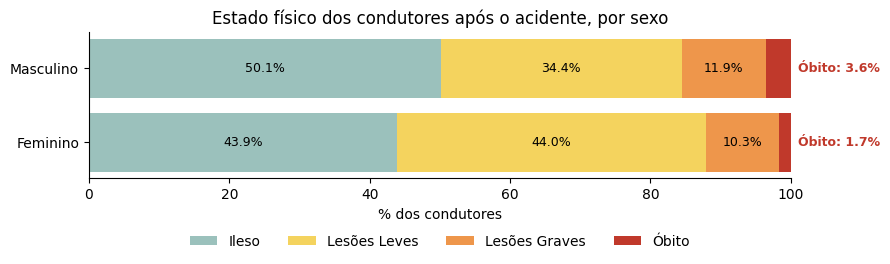

In [ ]:
cores = {"Ileso": "#9bc1bc", "Lesões Leves": "#f4d35e", "Lesões Graves": "#ee964b", "Óbito": "#c0392b"}

fig, ax = plt.subplots(figsize=(9, 3))
esquerda = np.zeros(len(condutores))
for estado in ORDEM_ESTADO:
    valores = condutores[estado].values
    ax.barh(condutores.index, valores, left=esquerda, label=estado, color=cores[estado])
    for i, v in enumerate(valores):
        if v >= 4:
            ax.text(esquerda[i] + v / 2, i, f"{v:.1f}%", ha="center", va="center", fontsize=9)
        elif estado == "Óbito":  # fatia estreita: rótulo fora da barra
            ax.text(101, i, f"Óbito: {v:.1f}%", ha="left", va="center", fontsize=9,
                    color=cores["Óbito"], fontweight="bold")
    esquerda += valores

ax.set_xlim(0, 100)
ax.set_xlabel("% dos condutores")
ax.set_title("Estado físico dos condutores após o acidente, por sexo")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig(SAIDA / "graficos" / "gravidade_condutores_por_sexo.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.3 Causas principais por sexo do condutor

A causa registrada pela PRF é da **ocorrência**, não de cada condutor. Num acidente com dois veículos, a mesma causa aparece para os dois motoristas. Por isso, olho também os acidentes com **um único veículo**, nos quais não há dúvida sobre quem estava dirigindo.

In [ ]:
causas_sexo = con.sql("""
SELECT e.sexo,
       c.causa_acidente,
       f.veiculos = 1 AS veiculo_unico,
       COUNT(*) AS condutores
FROM fato_envolvido e
JOIN fato_ocorrencia f ON e.id = f.id
JOIN dim_causa c       ON f.sk_causa = c.sk_causa
WHERE e.tipo_envolvido = 'Condutor'
  AND e.sexo IN ('Masculino', 'Feminino')
  AND c.causa_acidente IS NOT NULL
GROUP BY ALL
""").df()

def top_causas(df, n=8):
    tabela = df.pivot_table(index="causa_acidente", columns="sexo", values="condutores",
                            aggfunc="sum", fill_value=0)
    pct = (tabela / tabela.sum() * 100).round(2)
    principais = tabela.sum(axis=1).nlargest(n).index
    return pct.loc[principais]

causas_todos = top_causas(causas_sexo)
causas_veiculo_unico = top_causas(causas_sexo[causas_sexo["veiculo_unico"]])

display(causas_todos)
display(causas_veiculo_unico)

sexo,Feminino,Masculino
causa_acidente,,
Reação tardia ou ineficiente do condutor,15.54,14.54
Ausência de reação do condutor,14.83,14.38
Acessar a via sem observar a presença dos outros veículos,14.50,11.24
Condutor deixou de manter distância do veículo da frente,9.43,7.90
Manobra de mudança de faixa,7.62,6.57
Ingestão de álcool pelo condutor,3.12,4.97
Velocidade Incompatível,3.26,4.92
Transitar na contramão,2.74,4.51


sexo,Feminino,Masculino
causa_acidente,,
Ausência de reação do condutor,22.51,19.34
Reação tardia ou ineficiente do condutor,22.06,17.92
Demais falhas mecânicas ou elétricas,6.96,9.68
Velocidade Incompatível,6.58,8.91
Ingestão de álcool pelo condutor,3.66,7.28
Condutor Dormindo,4.42,5.03
Animais na Pista,3.65,5.12
Avarias e/ou desgaste excessivo no pneu,4.16,4.41


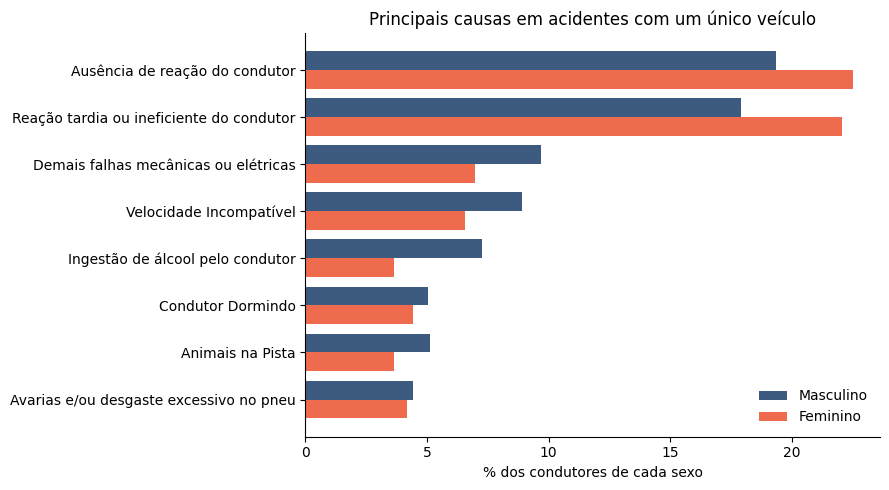

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
dados = causas_veiculo_unico.iloc[::-1]
y = np.arange(len(dados))
ax.barh(y + 0.2, dados["Masculino"], height=0.4, label="Masculino", color="#3d5a80")
ax.barh(y - 0.2, dados["Feminino"], height=0.4, label="Feminino", color="#ee6c4d")
ax.set_yticks(y)
ax.set_yticklabels([c if len(c) <= 45 else c[:44] + "…" for c in dados.index])
ax.set_xlabel("% dos condutores de cada sexo")
ax.set_title("Principais causas em acidentes com um único veículo")
ax.legend(frameon=False)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig(SAIDA / "graficos" / "causas_veiculo_unico_por_sexo.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Conclusões e limitações

**[Preencha após executar, usando os números das seções 9 e 10]**

**O que os dados mostram**

- Entre os condutores, homens representam ___% dos registros com sexo informado.
- A taxa de óbito é de ___% entre condutores homens e ___% entre condutoras mulheres.
- O V de Cramér é de ___, uma associação ___ (muito pequena / pequena / moderada) entre sexo e gravidade.
- Nos acidentes com um único veículo, as causas mais frequentes entre homens são ___ e entre mulheres ___.

**O que os dados não permitem afirmar**

- **Exposição:** a base não informa quantos quilômetros cada grupo dirige nem quantos condutores de cada sexo existem. Homens aparecem mais também porque dirigem mais, sobretudo em rodovias federais. Um próximo passo é normalizar pela frota de habilitados por sexo, publicada pelo Senatran.
- **Causa da ocorrência:** a causa é registrada por acidente, não por condutor. Por isso a análise de veículo único é a mais confiável para atribuir causa.
- **Associação não é causalidade:** idade, tipo de veículo, horário e tipo de via também influenciam a gravidade.
- **Dados ausentes:** registros com sexo ou estado físico não informados ficaram fora dos percentuais (veja o registro de qualidade).
- **2026 parcial:** os totais de 2026 não são comparáveis aos de anos completos.

## 12. Próximo passo: dashboard no Power BI

**Carga:** no Power BI Desktop, use *Obter dados → Parquet* para cada arquivo da pasta `saida/modelo_estrela`.

**Relacionamentos** (todos de um para muitos, com filtro em direção única):

| Dimensão | Fato |
|---|---|
| `dim_data[sk_data]` | `fato_ocorrencia[sk_data]` e `fato_envolvido[sk_data]` |
| `dim_local[sk_local]` | `fato_ocorrencia[sk_local]` e `fato_envolvido[sk_local]` |
| `dim_causa[sk_causa]` | `fato_ocorrencia[sk_causa]` e `fato_envolvido[sk_causa]` |
| `dim_tipo_acidente[sk_tipo]` | `fato_ocorrencia[sk_tipo]` e `fato_envolvido[sk_tipo]` |

Marque `dim_data` como tabela de datas.

**Medidas DAX** (as mesmas definições do dicionário de KPIs):

```
Ocorrências = COUNTROWS ( fato_ocorrencia )
Envolvidos = COUNTROWS ( fato_envolvido )
Óbitos = SUM ( fato_envolvido[obito] )
Envolvidos com estado informado =
    CALCULATE ( [Envolvidos], NOT ISBLANK ( fato_envolvido[estado_fisico] ) )
Taxa de letalidade = DIVIDE ( [Óbitos], [Envolvidos com estado informado] )
Índice de gravidade =
    DIVIDE ( SUM ( fato_envolvido[vitima_grave] ), [Envolvidos com estado informado] )
% ocorrências fatais =
    DIVIDE ( CALCULATE ( [Ocorrências], fato_ocorrencia[mortos] > 0 ), [Ocorrências] )
Taxa de letalidade condutores =
    CALCULATE ( [Taxa de letalidade], fato_envolvido[tipo_envolvido] = "Condutor" )
```

**Páginas sugeridas**

1. **Visão geral:** cartões com os KPIs, evolução mensal de ocorrências e óbitos, mapa por UF.
2. **Perfil do condutor:** gravidade por sexo e faixa etária, com filtro de tipo de envolvido.
3. **Causas:** principais causas, com filtro de veículo único e de sexo do condutor.
4. **Qualidade dos dados:** tabela do `registro_qualidade.csv`, que mostra ao avaliador o cuidado com os dados.